# Basic States — Qiskit Implementation

**Primitive:** Basic States (computational basis state preparation)

**SETUP**
- N QUBITS: 2
- TARGET STATE: `|10>` (qubit 1 = 1, qubit 0 = 0)
- QUBIT ORDERING: qubit 0 = rightmost bit in printed bitstring (Qiskit's native convention)
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**IMPORTANT: Run every cell in order, top to bottom** (Kernel → Restart & Run All). Cells
below rely on the imports and constants defined in the first code cell — running any cell
in isolation without that one first will raise a `NameError`.

In [1]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering -- not pulled in
# automatically by the base qiskit install, so it must be listed explicitly.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 1.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 33.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 51.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 72.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 3.9 MB/s eta 0:00:00


In [2]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# --- SETUP constants (all cells below use these — defined once, here) ---
N_QUBITS = 2
TARGET_STATE = "10"          # bitstring in the ordering convention: qubit0=rightmost
SHOTS = 10000
SEED = 42

# Precompute which qubit indices get an X gate
bits_msb_first = TARGET_STATE
bits_for_qubit = bits_msb_first[::-1]   # index q -> bit assigned to qubit q
qubits_to_flip = [q for q in range(N_QUBITS) if bits_for_qubit[q] == "1"]
print("Qubits to flip with X:", qubits_to_flip)

Qubits to flip with X: [1]


## 1. Build the circuit explicitly, gate by gate

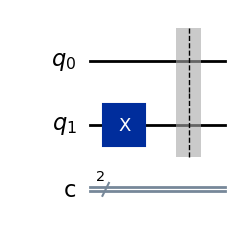

In [3]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="basic_states")

for q in range(N_QUBITS):
    if bits_for_qubit[q] == "1":
        qc.x(q)  # Basis-state preparation: Pauli-X flips |0> -> |1> on qubit q

qc.barrier()
qc.draw(output="mpl")

## 2. Draw the circuit and save to file

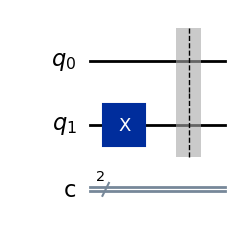

In [4]:
fig = qc.draw(output="mpl")
fig.savefig("basic_states_qiskit_circuit.png", bbox_inches="tight")
fig

## 3. Explicit matrix representation of the key operator (Pauli-X)

In [5]:
X_matrix = np.array([[0, 1],
                      [1, 0]], dtype=complex)

print("Single-qubit Pauli-X gate matrix:")
print(X_matrix)

Single-qubit Pauli-X gate matrix:
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]


In [6]:
prep_circuit = QuantumCircuit(N_QUBITS, name="prep_only")
for q in range(N_QUBITS):
    if bits_for_qubit[q] == "1":
        prep_circuit.x(q)

full_op = Operator(prep_circuit)
print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator (basis {{|00>, |01>, |10>, |11>}}):")
print(np.round(full_op.data.real, 4) if np.allclose(full_op.data.imag, 0) else np.round(full_op.data, 4))

Full 4x4 operator (basis {|00>, |01>, |10>, |11>}):
[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


## 4. Exact statevector (before measurement), global-phase normalized

In [7]:
sv = Statevector.from_instruction(qc)
amps = sv.data.copy()

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_norm, bitstrings = normalize_global_phase(amps, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector probabilities (qubit0 = rightmost):
{'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(1.0), '11': np.float64(0.0)}


**Ordering note:** Qiskit's `Statevector` already indexes amplitudes with qubit 0 as the
least-significant (rightmost) bit of the binary index — matches the SETUP convention
directly, so no reversal was needed here.

## 5. Measurement: add measurements, run AerSimulator, plot histogram

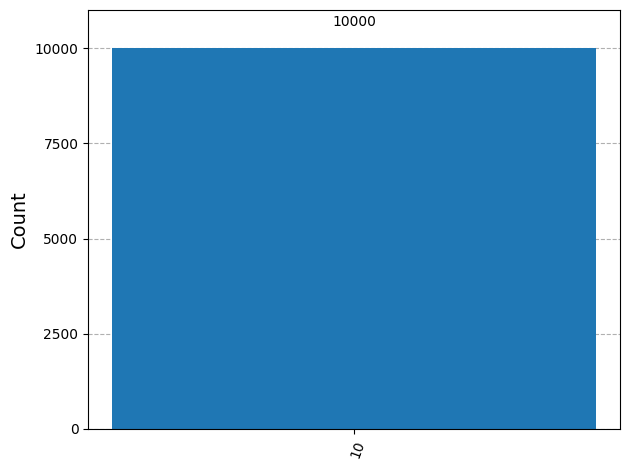

In [8]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
counts = result.get_counts()

fig2 = plot_histogram(counts)
fig2.savefig("basic_states_qiskit_histogram.png", bbox_inches="tight")
fig2

In [9]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'10': 1.0}


## 6. Circuit resource counts

In [10]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")

Depth: 2
Gate/operation count: 3


## 7. Convention notes

In [11]:
print("Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the")
print("rightmost (least-significant) bit of the printed bitstring, matching this notebook's")
print("SETUP convention exactly -> NO reversal applied.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")

Bit ordering: Qiskit's Statevector and get_counts() both natively use qubit 0 as the
rightmost (least-significant) bit of the printed bitstring, matching this notebook's
SETUP convention exactly -> NO reversal applied.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.


## Final result (for diffing against the CUDA-Q version)

In [12]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'00': np.float64(0.0), '01': np.float64(0.0), '10': np.float64(1.0), '11': np.float64(0.0)}
